In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [4]:
prefix = '/mnt/staging/' # or
# prefix = '/scratch/' #for s1n3/4
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"


fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"

figure_config_root = str(PREPARES / "config") + "/"
epochs_rest_root = str(PREPARES / "epochs-rest") + "/"

mouse='cm242'

In [5]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]

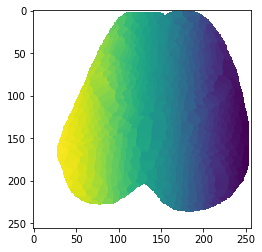

In [6]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [124]:
mouse_id = mouse
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse_id)
sensory_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse_id)

sensory_ind['RM']=sensory_ind['mouth']
sensory_ind['LM']=3
M2_ind['LM']=3

sensory_ind['RM'] = 462
temp = sensory_ind['RW'] 
sensory_ind['RW'] = sensory_ind['LW']
sensory_ind['LW'] = temp

sensory_ind['LALM']=64
sensory_ind['RALM']=400

sensory_ind['LV']=119
sensory_ind['RV']= 416

sensory_ind['LRSP'] = 241
sensory_ind['RRSP'] = 331

sensory_ind['RFP_M1_extra'] = 433 # cm242
sensory_ind['LFP_M1_extra'] = 69 # cm242

sensory_ind['RholeMOp'] = 392 # cm242
sensory_ind['LholeMOp'] = 90 # cm242

sensory_ind['Rposterior']=435 # cm242
sensory_ind['Lposterior']=128 # cm242

M1_ind_from_coherence = load_pickle(fetch_path_M1+'M1_ind_'+mouse)

# load full rest data

In [29]:
load_filename = fetch_path_M1+'final_lick_'+mouse+'_MM_jrgeco_'+mouse
hf = h5py.File(load_filename, 'r')
MM_jrgeco_REST = np.array(hf.get('MM_jrgeco_REST'))
t_stop_resting = np.array(hf.get('t_stop_resting'))
hf.close()





In [30]:
H_rest = getH_4D(MM_jrgeco_REST,IDX_sorted)

In [31]:
H_rest.shape

(500, 500, 42)

**get rid of midline**

In [32]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
        mask_midline = np.array(f_midline['mask_midline']).T

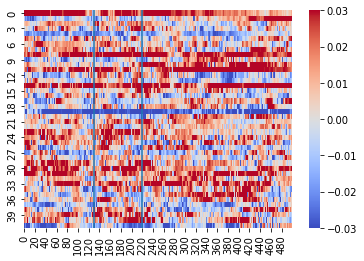

In [33]:
T_PRE_REST = 130
T_STOP_REST = 220
sns.heatmap(H_rest[sensory_ind['RALM'],:,:].T,vmin=-0.03,vmax=0.03,cmap='coolwarm')
plt.axvline(T_PRE_REST);plt.axvline(T_STOP_REST)

In [73]:
B = len(t_stop_resting)
concat_jrgeco_full_rest = np.empty((256,256,0))
for i_bout in range(20,B):
    concat_jrgeco_full_rest = np.append(concat_jrgeco_full_rest,
                    MM_jrgeco_REST[:,:,T_PRE_REST+20:t_stop_resting[i_bout]-20,i_bout],
                    axis=2)

# concat_jrgeco_full_rest = []
# for i_bout in range(B):
#     concat_jrgeco_full_rest.append(
#                     MM_jrgeco_REST[:,:,T_PRE_REST:t_stop_resting[i_bout],i_bout])
# concat_jrgeco_full_rest = np.concatenate(concat_jrgeco_full_rest,axis=2)

In [75]:
concat_jrgeco_full_rest.shape

(256, 256, 4597)

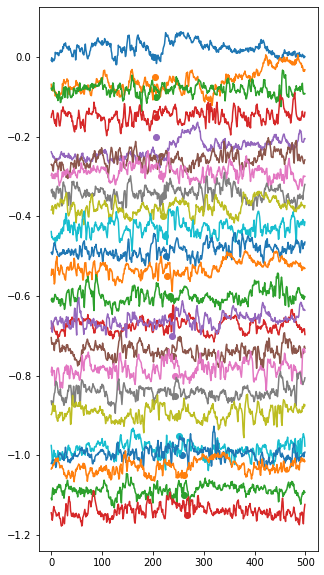

In [76]:
plt.figure(figsize=(5,10))
for i in range(24):
    plt.plot(H_rest[sensory_ind['RM'],:,i]-0.05*i)
    plot_here =t_stop_resting[i]
    if plot_here > 500:
        plot_here=500
    plt.scatter(plot_here,-0.05*i)

In [77]:
concat_jrgeco_full_rest  = np.multiply(concat_jrgeco_full_rest,np.repeat(mask_midline[:,:,np.newaxis],
                            repeats=concat_jrgeco_full_rest.shape[-1],axis=2))

In [78]:
concat_H = getH(concat_jrgeco_full_rest,IDX_sorted)

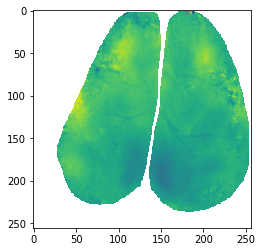

In [79]:
plt.imshow(concat_jrgeco_full_rest[:,:,100])

In [104]:
# OG:
# M2_ind['LHP']= M2_ind_from_coherence['LHP']
# M2_ind['RHP']= M2_ind_from_coherence['RHP']

In [136]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]


In [137]:
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp',
                 'Rposterior','Lposterior'
                 ]
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]

all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1


TCs_matrix = np.empty((0,concat_H.shape[1]))

for i_key,key in enumerate(all_bdps_extra):
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[key],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M2):
    bdp = key.split('_M2')[0]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    small_roi_tcs = np.nanmean(np.nanmean(
concat_jrgeco_full_rest[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    TCs_matrix = np.append(TCs_matrix,
                           small_roi_tcs[np.newaxis,:],
                           axis=0)

for i_key,key in enumerate(all_bdps_S1):
    bdp = key.split('_S1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[bdp],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M1):
    bdp = key.split('_M1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[M1_ind_from_coherence[bdp],np.newaxis,:],
                           axis=0)
    
# index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
# median_TCs_matrix = np.median(TCs_matrix[index_M2s+[0,1],:],axis=0)


# TCs_matrix[index_M2s+[0,1],:] = TCs_matrix[index_M2s+[0,1],:] - 5*median_TCs_matrix[np.newaxis,:]/len(index_M2s+[0,1]) 
# median_TCs_matrix = median_TCs_matrix#*len(index_M2s+[0]) 

# TCs_matrix = np.append(TCs_matrix,median_TCs_matrix[np.newaxis,:],axis=0)

# TCs_matrix = np.append(TCs_matrix,np.ones((1,concat_H.shape[1])),axis=0)



In [138]:
MM_jrgeco_reshape = concat_jrgeco_full_rest.reshape((256*256,-1))

# quick test on NNLS

In [139]:
total_T = TCs_matrix.shape[1]
to_cut = total_T % 4
if to_cut != 0:
    TCs_matrix = TCs_matrix[:,:-to_cut]
    MM_jrgeco_reshape = MM_jrgeco_reshape[:,:-to_cut]
total_T = total_T - to_cut

In [140]:
dict_ind ={}
split_size = int(total_T/4)
for fold_k in range(4):
    dict_ind[fold_k] = np.arange(split_size*fold_k,split_size*(fold_k+1))
    

In [141]:
import numpy as np
from scipy.optimize import minimize
from scipy.sparse import csr_matrix

def nnls_optimization(A, b):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = np.zeros(A.shape[1])

    # Bounds: 0 <= x
    bounds = [(0, None) for _ in range(A.shape[1])]

    # Optimize using 'L-BFGS-B' method for bound-constrained problems
    result = minimize(objective, x0, method='SLSQP', jac=objective_jac, bounds=bounds, options={'disp': False})

    return result.x

# # Example usage
# if __name__ == "__main__":
#     # Example with a larger dataset
#     np.random.seed(0)
#     A = np.random.rand(1000, 500)
#     b = np.random.rand(1000)
    
#     x = nnls_optimization(A, b)
#     print("Solution:", x)


In [142]:
start = time.time()
ind_here = dict_ind[0]
temp = Parallel(n_jobs=20)(delayed(nnls_optimization)(np.nan_to_num(TCs_matrix[:,:].T), 
    np.nan_to_num(MM_jrgeco_reshape[i_region,:])) for i_region in range(256*256))
full_M = np.vstack(temp)
end = time.time()
print(end - start)

137.42824172973633


In [143]:
mask = concat_jrgeco_full_rest[:,:,100]>-100
mask = mask.astype('float')
mask[mask==0]=np.nan
mask_reshape = mask.reshape((256*256))


W_S1M2M1 = full_M[mask_reshape==1,:]

# add M2 ones
W_S1M2M1_M2 = []
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    W_S1M2M1_M2.append(W_S1M2M1[:,ind_in_list])
W_S1M2M1_M2_sum = np.clip(np.sum(np.stack(W_S1M2M1_M2,0),0), 0, 1)
W_S1M2M1 = np.append(W_S1M2M1,W_S1M2M1_M2_sum[:,np.newaxis],axis=1)
# add cortical ones
W_S1M2M1 = np.append(W_S1M2M1,np.ones((len(W_S1M2M1_M2_sum),1)),axis=1)

W_masked = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked[:]=np.nan
W_masked[mask_reshape==1,:] = W_S1M2M1
W_masked = W_masked.reshape((256,256,-1))




In [144]:
# append median tc 
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
TCs_matrix=np.append(TCs_matrix,np.median(TCs_matrix[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
# append 1 tc 
TCs_matrix = np.append(TCs_matrix,np.ones((1,TCs_matrix.shape[1])),axis=0)

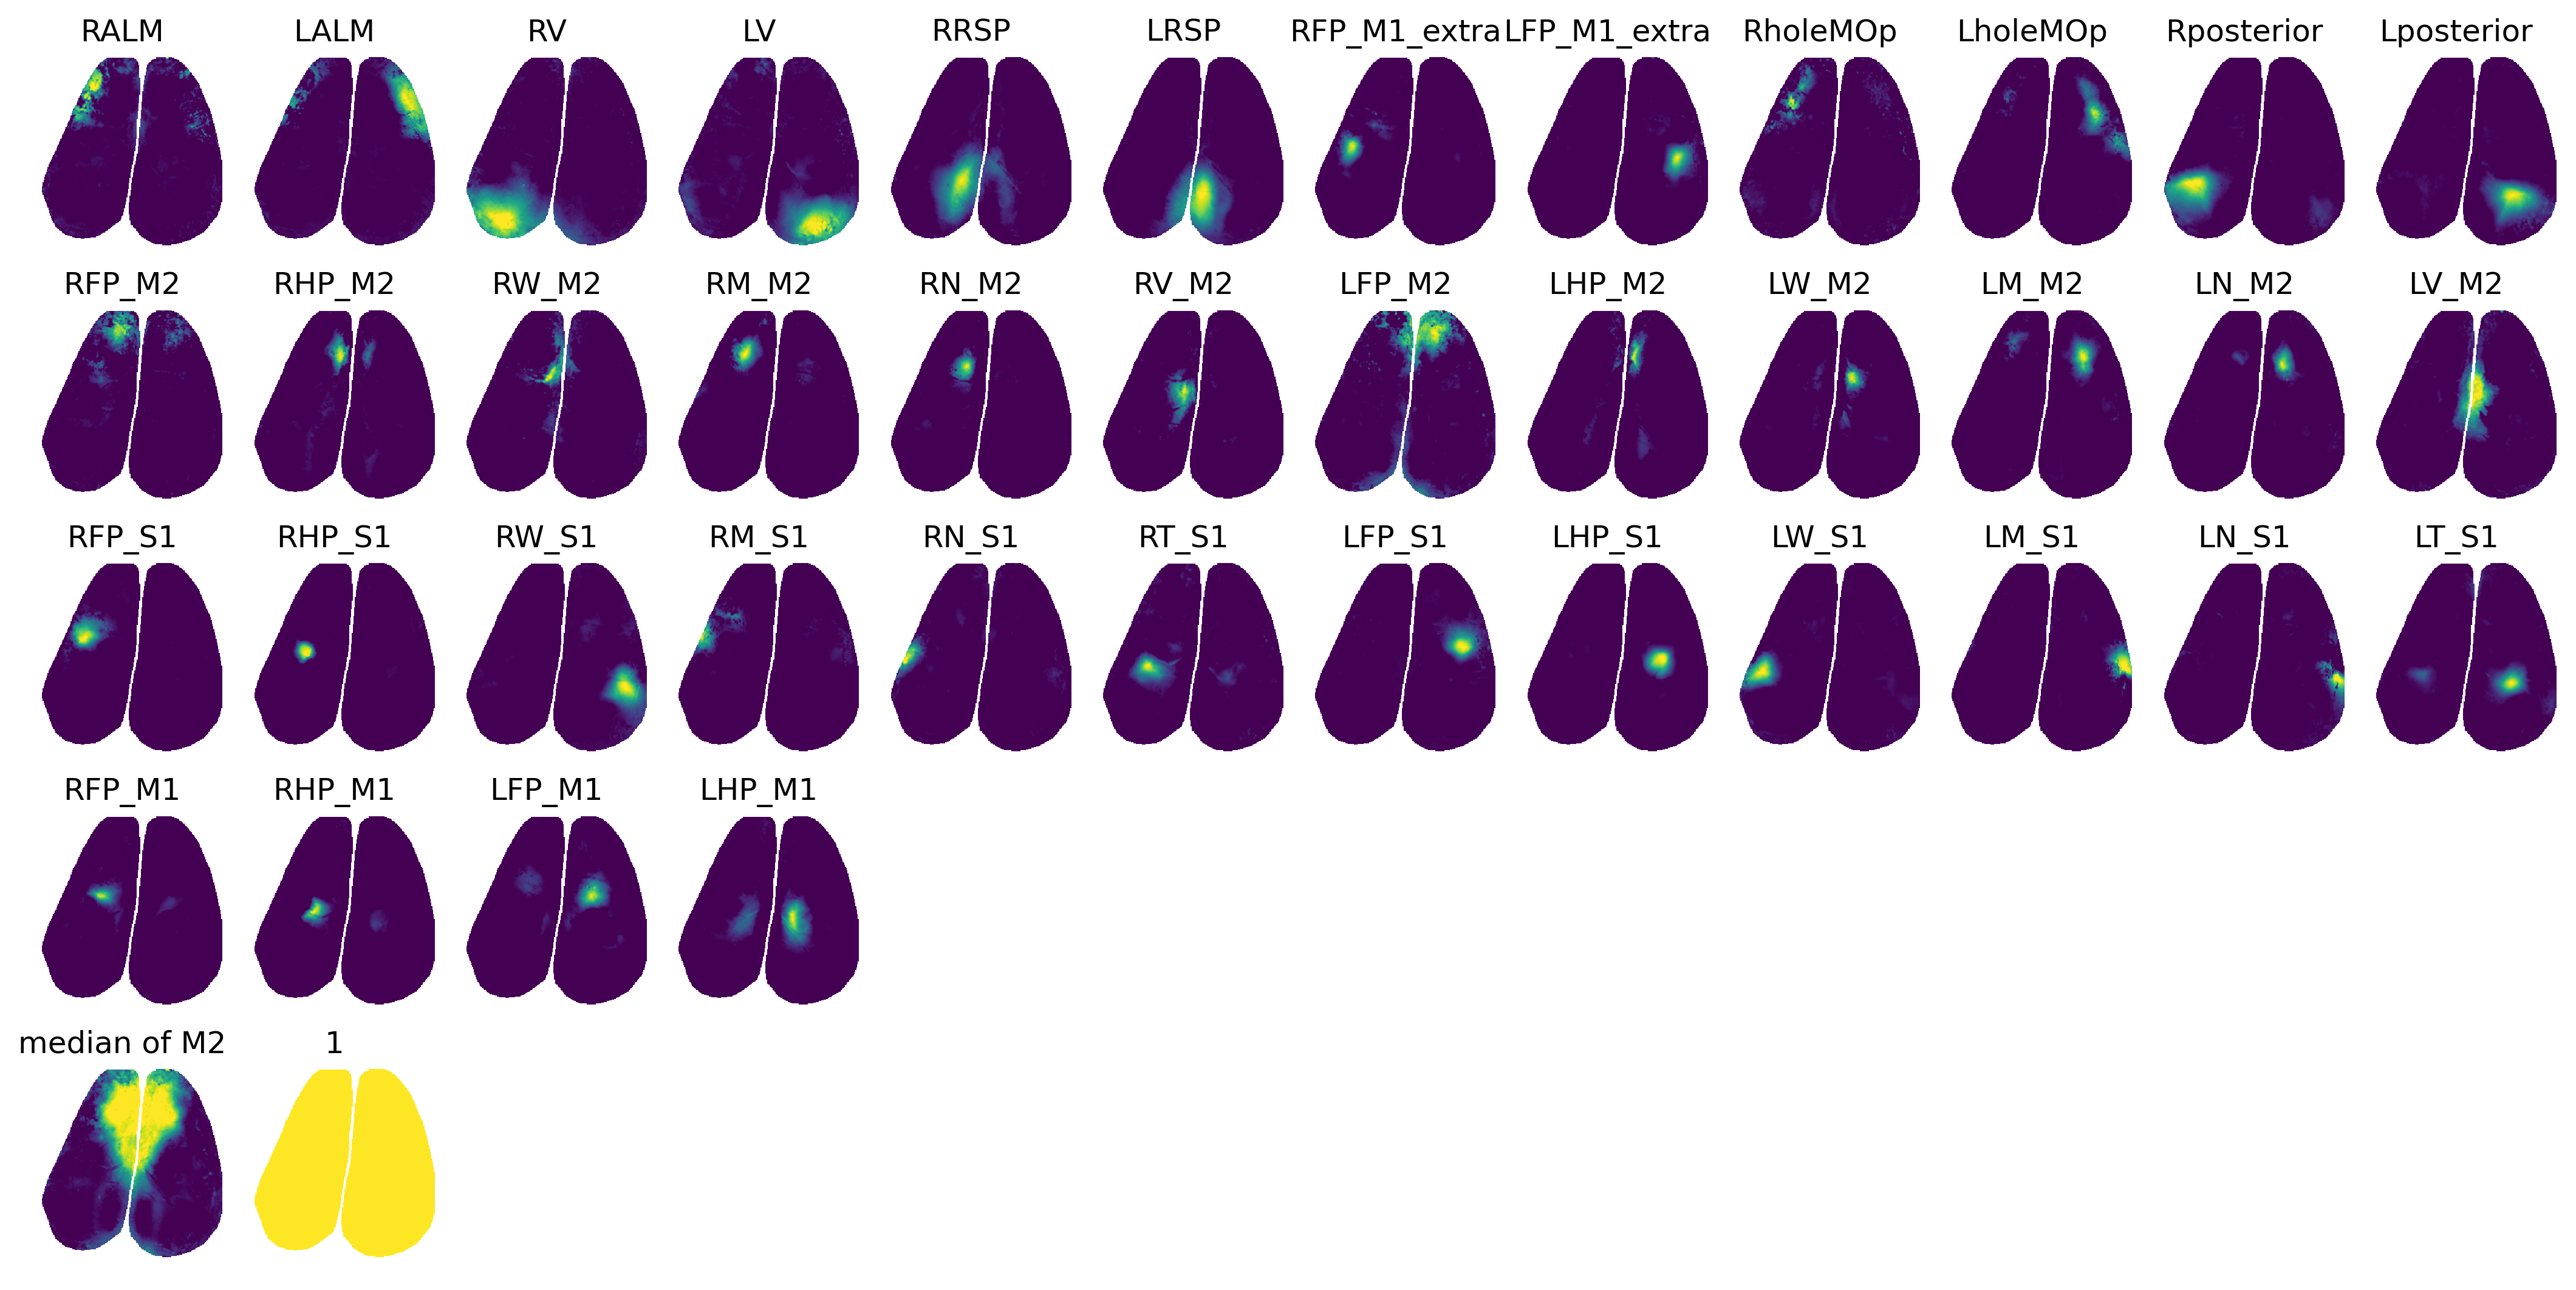

In [145]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+12:y_offset+17,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+18:y_offset+23,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)+2):
    exec("ax{} = fig.add_subplot(gs[y_offset+24:y_offset+29,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5

##########################################
##########################################
for i_key,key in enumerate(all_bdps_extra):
    ind_in_list = all_bdps.index(key)
    W_masked_2show = W_masked[:,:,ind_in_list]        
    exec("ax{}.imshow(W_masked_2show,vmin=0,vmax=1)".format(i_key))
    exec("ax{}.set_title(key)".format(i_key))
    # plt.axis('off')
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_S1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_M1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))

# plot median
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)
exec("ax{}.imshow(W_masked[:,:,-2],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('median of M2')".format(i_entry))

# plot 1
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)+1
exec("ax{}.imshow(W_masked[:,:,-1],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('1')".format(i_entry))

for i_ax in range(50):
    try:
        exec("ax{}.axis('off')".format(i_ax))
    except:
        continue

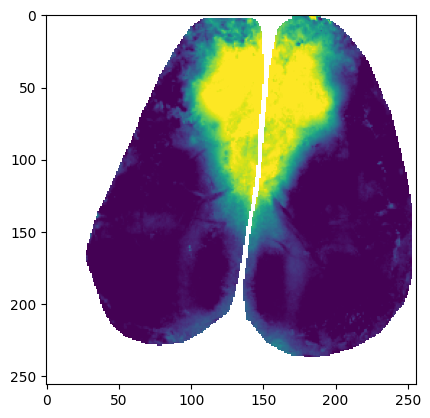

In [147]:
plt.imshow(W_masked[:,:,-2])
# ind_here = 435
# plt.scatter(node_coords[ind_here,1],node_coords[ind_here,0])
# ind_here = 128
# plt.scatter(node_coords[ind_here,1],node_coords[ind_here,0])

# now use the W to fit H

**now adding constraints**

In [148]:
def nnls_optimization_with_constraints(A, b,x_init,constraints):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = x_init #np.zeros(A.shape[1])
    # x0 = np.zeros(A.shape[1])

    
    result = minimize(objective, x0, method='SLSQP',constraints=constraints,jac=objective_jac, options={'disp': False})

    return result.x


In [149]:
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
  
def return_constraints(H_ROI,median_here,index_M2s,k):
    # Define the constraints
    constraints = []
    for i_M2 in index_M2s:
        constraints.append({
            'type': 'eq',
            'fun': lambda x, i_M2=i_M2: x[i_M2] - (H_ROI[i_M2] - x[-2])
        })
    constraints.append({'type': 'eq', 'fun': lambda x: x[-2] - k*median_here})  
    
    return constraints

In [156]:
save_root =  str(PREPARES / "CLS") + "/"

save_dict = {'full_M':full_M,
             # 'full_M_back_in_shape':full_M_back_in_shape,
            # 'full_nnls_spatial':full_nnls_spatial,
             'index_M2s':index_M2s,
             'W_S1M2M1':W_S1M2M1,
             'mask':mask,
             'TCs_matrix':TCs_matrix,
             'all_bdps_w_order_nnls':all_bdps,
             # 'mask_M2':mask_M2,
             'all_bdps_w_order':all_bdps,    
             'final_k':0.5
            }

save_pickle(save_dict,save_root+'M2S1M1_NNLS_spatial_'+mouse)



--------